# Notebook 07: Aspect-level analysis of the eight apps

The final pipeline (`sentiment_final.joblib` + expanded lexicon + the opinion scope that scored best on the gold set)
is run over every review. The comparisons then use 2024-2026 only (`ANALYSIS_START`), so all apps are judged
on their recent state (CBZ Touch has reviews back to 2016; the Super App only exists from April 2026).

Net sentiment of an aspect = (positive mentions - negative mentions) / all mentions, from -1 (all negative) to +1
(all positive). Cells based on fewer than 10 mentions are left blank: too few to say anything.

In [1]:
# Setup
import sys, warnings
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from absa.setup import ensure_resources
from absa import viz
ensure_resources()
viz.use_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

In [2]:
import json
from absa.config import ANALYSIS_START, APPS, TABLES_DIR, PROCESSED_DIR, SEED
from absa.data import load_reviews
from absa.aspects import AspectLexicon
from absa.pipeline import ABSAnalyzer

summary_file = TABLES_DIR / "06_summary.json"
STRATEGY = json.load(open(summary_file))["aspect_sentiment_best_scope"] if summary_file.exists() else "dependency"
print("opinion scope used:", STRATEGY)

reviews = load_reviews()
lex = AspectLexicon()
analyzer = ABSAnalyzer(lexicon=lex, strategy=STRATEGY)
opinions = analyzer.analyse_many(reviews)
opinions["aspect_name"] = opinions["aspect"].map(lambda a: lex.name(a) if a in lex.info else "General")
opinions["level"] = opinions["aspect"].map(lambda a: lex.info[a]["level"] if a in lex.info else "")
opinions.to_csv(PROCESSED_DIR / "absa_opinions.csv", index=False, encoding="utf-8-sig")
print(f"{len(opinions):,} opinions from {opinions['reviewId'].nunique():,} reviews "
      f"({(opinions['aspect'] != 'general').sum():,} about a specific aspect)")

opinion scope used: clause


10,336 opinions from 6,172 reviews (5,958 about a specific aspect)


In [3]:
recent = opinions[(opinions["at"] >= ANALYSIS_START) & (opinions["aspect"] != "general")].copy()
MIN_N = 10

def net_table(df, by):
    t = df.groupby(by)["sentiment"].value_counts().unstack(fill_value=0).reindex(
        columns=["negative", "neutral", "positive"], fill_value=0)
    t["n"] = t.sum(axis=1)
    t["net"] = (t["positive"] - t["negative"]) / t["n"]
    return t

nt = net_table(recent, ["app", "aspect"])
net = nt["net"].where(nt["n"] >= MIN_N).unstack()
counts = nt["n"].unstack().fillna(0).astype(int)
app_order = [a for a in APPS if a in net.index]
asp_order = recent["aspect"].value_counts().index.tolist()
print(f"{len(recent):,} aspect opinions in {recent['reviewId'].nunique():,} reviews since {ANALYSIS_START}")

3,844 aspect opinions in 2,061 reviews since 2024-01-01


## 1. The aspect and app map

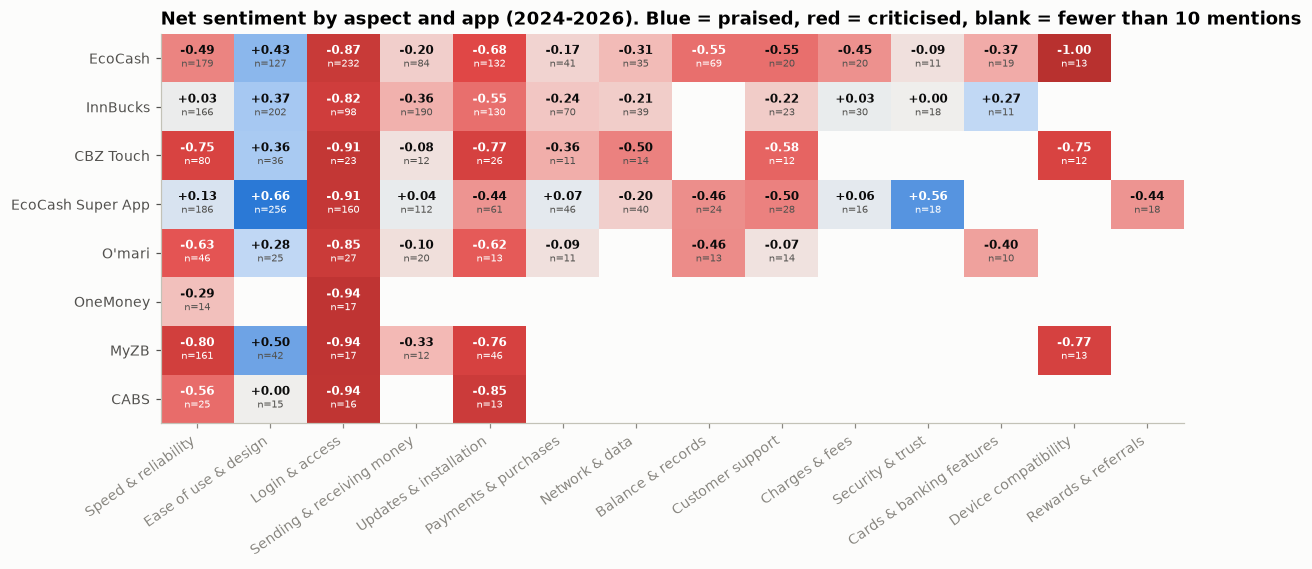

In [4]:
H = net.loc[app_order, asp_order]
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.imshow(H.values, cmap=viz.DIVERGING, vmin=-1, vmax=1, aspect="auto")
for i, a in enumerate(app_order):
    for j, s in enumerate(asp_order):
        v, n = H.values[i, j], counts.loc[a, s] if s in counts.columns else 0
        if np.isnan(v):
            continue
        ax.text(j, i, f"{v:+.2f}\n", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.55 else viz.INK, fontweight="bold")
        ax.text(j, i, f"\nn={n}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(v) > 0.55 else viz.INK_2)
ax.set_xticks(range(len(asp_order)), [lex.name(a) for a in asp_order], rotation=35, ha="right")
ax.set_yticks(range(len(app_order)), app_order)
ax.grid(False)
ax.set_title(f"Net sentiment by aspect and app ({ANALYSIS_START[:4]}-2026). Blue = praised, red = criticised, blank = fewer than {MIN_N} mentions")
viz.save(fig, "07_aspect_app_heatmap")
plt.show()

In [5]:
sov = pd.crosstab(recent["app"], recent["aspect"], normalize="index").loc[app_order, asp_order]
(sov * 100).round(0).astype(int).rename(columns=lex.name)

aspect,Speed & reliability,Ease of use & design,Login & access,Sending & receiving money,Updates & installation,Payments & purchases,Network & data,Balance & records,Customer support,Charges & fees,Security & trust,Cards & banking features,Device compatibility,Rewards & referrals
app,,,,,,,,,,,,,,
EcoCash,18,13,24,9,13,4,4,7,2,2,1,2,1,0
InnBucks,17,20,10,19,13,7,4,1,2,3,2,1,0,0
CBZ Touch,32,14,9,5,10,4,6,2,5,2,4,1,5,0
EcoCash Super App,19,26,16,11,6,5,4,2,3,2,2,1,1,2
O'mari,24,13,14,10,7,6,0,7,7,5,2,5,1,0
OneMoney,29,10,35,4,4,4,2,4,4,2,0,0,2,0
MyZB,51,13,5,4,15,1,1,2,2,1,1,0,4,0
CABS,27,16,18,4,14,1,5,4,0,1,1,4,2,0


What the map shows
* Login & access is the most criticised aspect for seven of the eight apps (net -0.82 to -0.94), and second for
  the old EcoCash app, where device compatibility is worse. OTP codes that never arrive, the OTP keyboard bug, devices
  that must be re-linked, fingerprint login that stops working. The problem is not specific to one company; it is the
  weak point of Zimbabwean mobile money and banking apps as a whole.
* Updates & installation are negative everywhere: new versions that stop opening, forced upgrades, removed features.
* Ease of use & design is praised for every app except CABS (neutral). Users like the apps *when they work*; the
  frustration is reliability and access, not design.
* Apps differ most on Speed & reliability: strongly negative for MyZB, CBZ Touch, O'mari and CABS, neutral or
  positive for InnBucks and the EcoCash Super App.

## 2. Top complaints per app, with evidence

In [6]:
rows = []
for app in app_order:
    d = recent[recent["app"] == app]
    neg = d[d["sentiment"] == "negative"]
    for aspect, n in neg["aspect"].value_counts().head(3).items():
        ex = neg[(neg["aspect"] == aspect) & neg["sentence"].str.len().between(30, 140)]
        quote = ex.sort_values("confidence", ascending=False)["sentence"].iloc[0] if len(ex) else ""
        rows.append({"app": app, "complaint": lex.name(aspect), "negative mentions": n,
                     "share of app's negatives": f"{n / len(neg):.0%}", "example": quote})
complaints = pd.DataFrame(rows)
complaints.to_csv(TABLES_DIR / "07_top_complaints.csv", index=False)
complaints

,app,complaint,negative mentions,share of app's negatives,example
0,EcoCash,Login & access,208,33%,poor app it doesn't register.l keep resending the OTP
1,EcoCash,Speed & reliability,121,19%,this App is not working stuck on OTP no keyboard appearing
2,EcoCash,Updates & installation,100,16%,"ever since latest update, cannot sign into app as it won't let me enter OTP"
3,InnBucks,Sending & receiving money,108,22%,I can't transfer money to my ecocash either it keeps saying error
4,InnBucks,Updates & installation,88,18%,"The old app was great, the new update doesnt work totally"
5,InnBucks,Login & access,81,17%,"It doesn't allow you to log in, doesn't send OTPs and the help WhatsApp doesn't ever work"
6,CBZ Touch,Speed & reliability,67,39%,"If l grant, it says full rights have been granted but does not open"
7,CBZ Touch,Updates & installation,22,13%,I changed my device and ever since l have been trying to install this app on new device to mo avail
8,CBZ Touch,Login & access,21,12%,"The app is not user friendly , can't log in, have tried many times to log in but am failing"
9,EcoCash Super App,Login & access,147,33%,The App does not allow me to enter the OTP


## 3. Natural experiment: old EcoCash app vs Super App

Same company, same customers, same tariffs, same network, same six months. The main thing that differs is the
app. This is the closest thing to a controlled experiment in the data.

Sanity check designed in advance (notebook 04): if the aspect analysis works, *service-level* aspects (fees,
support, transfers: set by the company) should differ less between the two apps than *app-level* aspects (speed,
login, updates, ease of use: set by the software). Differences come with 95% bootstrap intervals (reviews resampled
1,000 times).

In [7]:
start = opinions.loc[opinions["app"] == "EcoCash Super App", "at"].min()
eco = opinions[(opinions["brand"] == "EcoCash") & (opinions["at"] >= start) & (opinions["aspect"] != "general")]
rng = np.random.default_rng(SEED)

def net_of(d):
    return ((d["sentiment"] == "positive").sum() - (d["sentiment"] == "negative").sum()) / max(len(d), 1)

rows = []
for aspect, g in eco.groupby("aspect"):
    old, new = g[g["app"] == "EcoCash"], g[g["app"] == "EcoCash Super App"]
    if len(old) < 8 or len(new) < 8:
        continue
    diffs = []
    for _ in range(1000):
        o = old.iloc[rng.integers(0, len(old), len(old))]
        n_ = new.iloc[rng.integers(0, len(new), len(new))]
        diffs.append(net_of(n_) - net_of(o))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append({"aspect": aspect, "name": lex.name(aspect), "level": lex.info[aspect]["level"],
                 "n old": len(old), "n new": len(new), "net old": net_of(old), "net new": net_of(new),
                 "difference": net_of(new) - net_of(old), "ci_low": lo, "ci_high": hi,
                 "significant": not (lo <= 0 <= hi)})
exp = pd.DataFrame(rows).sort_values("difference")
exp.to_csv(TABLES_DIR / "07_ecocash_experiment.csv", index=False)
print(f"window: {start:%d %b %Y} onwards")
exp.round(2)

window: 23 Apr 2026 onwards


,aspect,name,level,n old,n new,net old,net new,difference,ci_low,ci_high,significant
0,connectivity,Network & data,service,8,40,0.00,-0.20,-0.20,-0.65,0.22,False
2,payments,Payments & purchases,service,9,46,0.11,0.07,-0.05,-0.58,0.49,False
1,login,Login & access,app,60,160,-0.90,-0.91,-0.01,-0.11,0.08,False
6,usability,Ease of use & design,app,16,256,0.62,0.66,0.04,-0.25,0.35,False
4,transactions,Sending & receiving money,service,13,112,0.00,0.04,0.04,-0.51,0.60,False
3,performance,Speed & reliability,app,34,186,-0.32,0.13,0.46,0.11,0.80,True
5,updates,Updates & installation,app,17,61,-0.94,-0.44,0.50,0.26,0.74,True


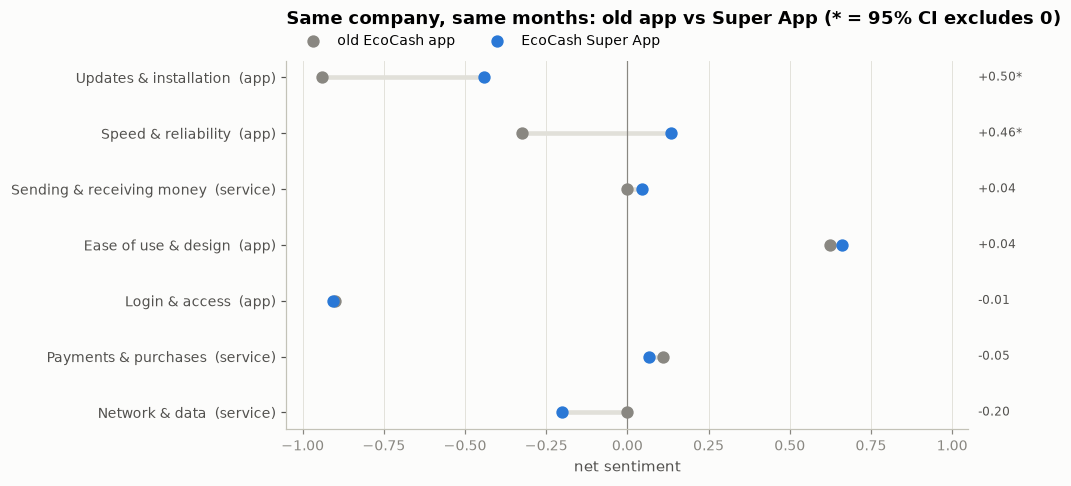

In [8]:
fig, ax = plt.subplots(figsize=(8, 0.45 * len(exp) + 1.2))
y = np.arange(len(exp))
for i, (o, n_) in enumerate(zip(exp["net old"], exp["net new"])):
    ax.plot([o, n_], [i, i], color=viz.GRID, lw=3, zorder=1)
ax.scatter(exp["net old"], y, color=viz.MUTED, s=50, zorder=2, label="old EcoCash app")
ax.scatter(exp["net new"], y, color=viz.BLUE, s=50, zorder=3, label="EcoCash Super App")
ax.set_yticks(y, [f"{n}  ({l})" for n, l in zip(exp["name"], exp["level"])])
for i, r in enumerate(exp.itertuples()):
    mark = "*" if r.significant else ""
    ax.text(1.08, i, f"{r.difference:+.2f}{mark}", va="center", fontsize=8, color=viz.INK_2)
ax.axvline(0, color=viz.MUTED, lw=0.8)
ax.set_xlim(-1.05, 1.05); ax.set_xlabel("net sentiment"); ax.grid(axis="y", visible=False)
ax.legend(ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Same company, same months: old app vs Super App (* = 95% CI excludes 0)", pad=24)
viz.save(fig, "07_ecocash_experiment")
plt.show()

In [9]:
lvl = exp.groupby("level")["difference"].agg(lambda s: s.abs().mean()).rename("mean |difference|")
lvl.to_frame().assign(aspects=exp.groupby("level").size()).round(3)

,mean |difference|,aspects
level,,
app,0.249,4
service,0.097,3


Read the chart together with the level table above:
* Two aspects improved significantly with the Super App: Updates & installation (net -0.94 to -0.44) and
  Speed & reliability (from -0.32 to +0.13). Both are app-level, which is what better software should change.
* Login & access did not move at all (from -0.90 to -0.91). OTP and device-linking problems carried straight over to the
  new app, the clearest actionable finding for EcoCash.
* Sanity check passed: the average size of the change is 0.25 for app-level aspects vs 0.10 for service-level
  aspects, and none of the service-level differences (payments, network, transfers) is significant. The analysis
  separates *software* from *service* as it should. A star rating could only have said "the new app is rated higher".
* Caveat: the old app has far fewer opinions in this window (e.g. 17 on updates), so its intervals are wide.

## 4. Mobile money vs banking apps

In [10]:
recent["type"] = recent["app"].map(lambda a: APPS[a]["type"])
tt = net_table(recent, ["type", "aspect"])
by_type = tt["net"].where(tt["n"] >= 15).unstack(0)
by_type["gap (mobile money - banking)"] = by_type["mobile money"] - by_type["banking"]
by_type.index = by_type.index.map(lex.name)
by_type.sort_values("gap (mobile money - banking)").round(2)

type,banking,mobile money,gap (mobile money - banking)
aspect,,,
Device compatibility,-0.78,-0.88,-0.10
Sending & receiving money,-0.18,-0.20,-0.02
Balance & records,-0.53,-0.52,0.01
Login & access,-0.93,-0.87,0.06
Ease of use & design,0.37,0.50,0.13
Updates & installation,-0.78,-0.59,0.19
Customer support,-0.59,-0.37,0.22
Network & data,-0.48,-0.24,0.23
Speed & reliability,-0.76,-0.15,0.61


Banking apps (CBZ Touch, MyZB, CABS) are judged much more harshly on Speed & reliability (net -0.76 vs -0.15 for
mobile money, a gap of 0.61), while they do better on balances and transfers. Login is equally bad in both groups.

## 5. How have the main complaints moved over time?

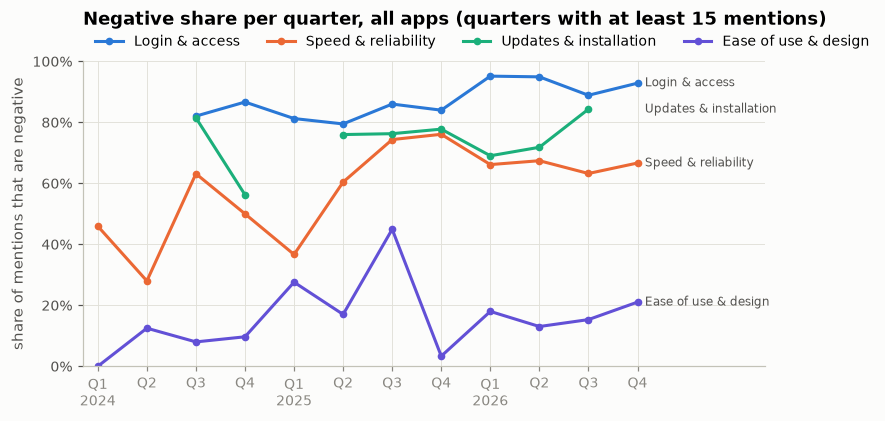

In [11]:
trend_aspects = ["login", "performance", "updates", "usability"]
t = opinions[(opinions["at"] >= "2024-01-01") & opinions["aspect"].isin(trend_aspects)].copy()
t["quarter"] = t["at"].dt.to_period("Q")
q = t.groupby(["quarter", "aspect"])["sentiment"].apply(lambda s: (s == "negative").mean()).unstack()
qn = t.groupby(["quarter", "aspect"]).size().unstack()
q = q.where(qn >= 15)
palette = dict(zip(trend_aspects, ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]))
fig, ax = plt.subplots(figsize=(8, 3.6))
for a in trend_aspects:
    ax.plot(range(len(q)), q[a], marker="o", ms=4, color=palette[a], label=lex.name(a))
    last = q[a].dropna()
    if len(last):
        ax.text(len(q) - 0.85, last.iloc[-1], lex.name(a), fontsize=8, color=viz.INK_2, va="center")
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("share of mentions that are negative"); ax.set_xlim(-0.3, len(q) + 1.6)
ax.set_xticks(range(len(q)), [f"Q{p.quarter}\n{p.year}" if p.quarter == 1 else f"Q{p.quarter}" for p in q.index])
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Negative share per quarter, all apps (quarters with at least 15 mentions)", pad=24)
viz.save(fig, "07_trends")
plt.show()

## 6. What people say: word clouds

Each word is sized by how many sentences use it and coloured by the average sentiment of those sentences: red words
come mostly from complaints, blue words mostly from praise, grey words from both (`src/absa/clouds.py`). Splitting the
cloud into complaint words and praise words makes both sides readable.

In [12]:
from absa.clouds import word_stats, make_cloud

stats = word_stats(opinions[opinions["at"] >= ANALYSIS_START])
stats.head(15).round(2)

,word,n,net
0,good,829,0.80
1,excellent,216,0.96
2,easy,205,0.93
3,otp,192,-0.95
4,great,186,0.80
5,best,176,0.94
6,money,165,-0.17
7,working,145,-0.79
8,fast,142,0.90
9,new,136,-0.79


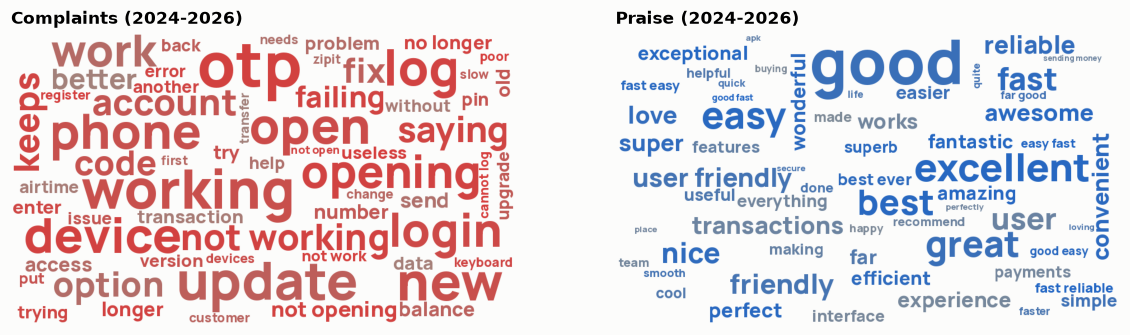

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, (title, part) in zip(axes, [("Complaints", stats[stats["net"] < -0.2]),
                                    ("Praise", stats[stats["net"] > 0.2])]):
    ax.imshow(make_cloud(part, width=900, height=520, max_words=60, background=viz.SURFACE))
    ax.set_title(f"{title} (2024-2026)", fontsize=11)
    ax.axis("off")
viz.save(fig, "07_word_clouds")
plt.show()

The complaint side is about access and reliability: otp, log in, device, not working, opening, code, keeps, update.
The praise side is about ease and speed: easy, fast, user friendly, reliable, convenient. The same story as the
aspect heatmap, told by the reviewers' own words.

## 7. Why aspects beat star ratings

Two apps can have similar average stars and very different problems. Below, each app's average star rating sits next to
its two most-criticised and two most-praised aspects (at least 10 mentions). This is the actionable view the proposal
promised: a star rating says *how much* users are unhappy; the aspect profile says *about what*. (OneMoney has too
few opinions for any aspect to be clearly praised.)

In [14]:
rows = []
for app in app_order:
    s = nt.loc[app]; s = s[s["n"] >= MIN_N].sort_values("net")
    rev = reviews[(reviews["app"] == app) & (reviews["at"] >= ANALYSIS_START)]
    rows.append({"app": app, "avg stars": round(rev["score"].mean(), 2), "reviews": len(rev),
                 "most criticised": ", ".join(f"{lex.name(a)} ({v:+.2f})" for a, v in s["net"].head(2).items()),
                 "most praised": ", ".join(f"{lex.name(a)} ({v:+.2f})" for a, v in s["net"].tail(2)[::-1].items())})
profile = pd.DataFrame(rows).sort_values("avg stars")
profile.to_csv(TABLES_DIR / "07_app_profiles.csv", index=False)
profile

,app,avg stars,reviews,most criticised,most praised
6,MyZB,2.76,296,"Login & access (-0.94), Speed & reliability (-0.80)","Ease of use & design (+0.50), Sending & receiving money (-0.33)"
7,CABS,2.98,84,"Login & access (-0.94), Updates & installation (-0.85)","Ease of use & design (+0.00), Speed & reliability (-0.56)"
4,O'mari,3.09,161,"Login & access (-0.85), Speed & reliability (-0.63)","Ease of use & design (+0.28), Customer support (-0.07)"
0,EcoCash,3.15,795,"Device compatibility (-1.00), Login & access (-0.87)","Ease of use & design (+0.43), Security & trust (-0.09)"
2,CBZ Touch,3.19,223,"Login & access (-0.91), Updates & installation (-0.77)","Ease of use & design (+0.36), Sending & receiving money (-0.08)"
5,OneMoney,3.34,74,"Login & access (-0.94), Speed & reliability (-0.29)","Speed & reliability (-0.29), Login & access (-0.94)"
1,InnBucks,3.99,1340,"Login & access (-0.82), Updates & installation (-0.55)","Ease of use & design (+0.37), Cards & banking features (+0.27)"
3,EcoCash Super App,4.04,1195,"Login & access (-0.91), Customer support (-0.50)","Ease of use & design (+0.66), Security & trust (+0.56)"
